# Xenium Prime 5K Breast — GNN communication niches

Executed real-data analysis of one breast tissue. Each of the 699,110 cell-centered, 30-cell microenvironments has one nonnegative 32-program embedding. This notebook only reads saved results; opening or rerunning it does not train a model. This independent downstream analysis does not enter the clinical CCC/Cox mainline.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, '/home/xueshuailin/CCC_Phe/src')
from phenoniche.gnn.reporting import GNNReport
OUTPUT = Path('/home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn')
report = GNNReport(OUTPUT)
pd.set_option('display.max_colwidth', 150)
pd.set_option('display.max_rows', 200)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. Data scale, fixed CCC features, and model configuration

Broad cell labels are provisional, replayed from outcome-blind expression clusters and fixed markers. Unassigned cells are retained. All retained directed CCC definitions and feature order are unchanged. Spatial blocks are 400 µm; boundary centers are purged so physical cells never cross training/validation/test folds. Purged centers are mapped only after training. Biological scoring targets are excluded from encoder genes and its library-size input.

In [2]:
display(report.overview())
display(pd.Series(report.config).to_frame('Configuration'))
display(report.features.head(12))
for branch in ('upstream','downstream'):
    audit=report.audit[branch]
    display(pd.Series({k:v for k,v in audit.items() if k not in ('independent_score_genes','skipped_entities','excluded_LR_score_genes','encoder_genes')}).to_frame(branch))

,Value
Cells / microenvironments,699110
Xenium genes,5101
Fixed directed CCC features,450
Effective training features,447
GNN input genes (excluding activity targets),512
Communication programs,32
Selected niches,8
Biological loss mode,both
Upstream prior modules,1547
Downstream prior modules,132


,Configuration
seed,40700
split_seed,40700
programs,32
hidden,64
encoder_genes,512
batch_size,512
max_epochs,40
patience,6
lr,0.003
weight_decay,0.0001


,feature_id,flat_feature_index,sender,receiver,lr_id,ligand,receptor,ccc
0,0,31701,Endothelial,Endothelial,CommuSpace_HS_00391,APP,FLT1,Endothelial → Endothelial | APP–FLT1
1,1,31974,Endothelial,Endothelial,CommuSpace_HS_01082,CCN1,ITGB3,Endothelial → Endothelial | CCN1–ITGB3
2,2,32155,Endothelial,Endothelial,CommuSpace_HS_01731,COL4A1,CD93,Endothelial → Endothelial | COL4A1–CD93
3,3,32163,Endothelial,Endothelial,CommuSpace_HS_01751,COL4A2,CD93,Endothelial → Endothelial | COL4A2–CD93
4,4,32169,Endothelial,Endothelial,CommuSpace_HS_01767,COL4A2,ITGB3,Endothelial → Endothelial | COL4A2–ITGB3
5,5,32460,Endothelial,Endothelial,CommuSpace_HS_02648,ENG,BMPR2,Endothelial → Endothelial | ENG–BMPR2
6,6,33638,Endothelial,Endothelial,CommuSpace_HS_06138,PECAM1,ITGB3,Endothelial → Endothelial | PECAM1–ITGB3
7,7,33639,Endothelial,Endothelial,CommuSpace_HS_06139,PECAM1,PECAM1,Endothelial → Endothelial | PECAM1–PECAM1
8,8,33776,Endothelial,Endothelial,CommuSpace_HS_06474,PTPRM,PTPRM,Endothelial → Endothelial | PTPRM–PTPRM
9,9,34075,Endothelial,Endothelial,CommuSpace_HS_07380,THBS1,ITGB3,Endothelial → Endothelial | THBS1–ITGB3


,upstream
provenance,"{'status': 'verified', 'rows': 57770, 'database': 'CollecTRI', 'version': 'OmniPath human snapshot 2026-10-13', 'url': 'https://omnipathdb.org/int..."
status,mapped
modules,1547
mapped_features,442
feature_match_rate,0.982222
uncovered_feature_indices,"[102, 108, 109, 126, 148, 149, 297, 347]"
prior_entities,1175
entities_on_panel,533
prior_target_genes,6488
target_genes_on_panel,2878


,downstream
provenance,"{'status': 'verified', 'rows': 5100, 'database': 'NicheNet', 'version': 'NicheNet-v2 human Zenodo 7074291 (2022-09-13)', 'url': 'https://zenodo.or..."
status,mapped
modules,132
mapped_features,420
feature_match_rate,0.933333
uncovered_feature_indices,"[26, 27, 42, 98, 99, 100, 101, 102, 105, 122, 123, 124, 132, 139, 143, 144, 159, 163, 256, 257, 258, 263, 264, 265, 266, 270, 322, 341, 367, 381]"
prior_entities,51
entities_on_panel,51
prior_target_genes,1414
target_genes_on_panel,545


## 2. Training and CCC reconstruction

$Z=\mathrm{softplus}(a)\,\mathrm{softmax}(p)$; $\hat C=ZH$, with $H\geq0$ and unit row sums. The objective is masked, feature-scaled CCC Huber error + 0.1 × (upstream + downstream residual alignment) + 0.005 × dictionary/program regularization. Biological alignment is calibrated on training cells after removing cell-type, local-composition, and expression-state baselines. Conflicting auxiliary gradients are projected against the CCC gradient. Biological targets are regulon/response proxies, not causal readouts.

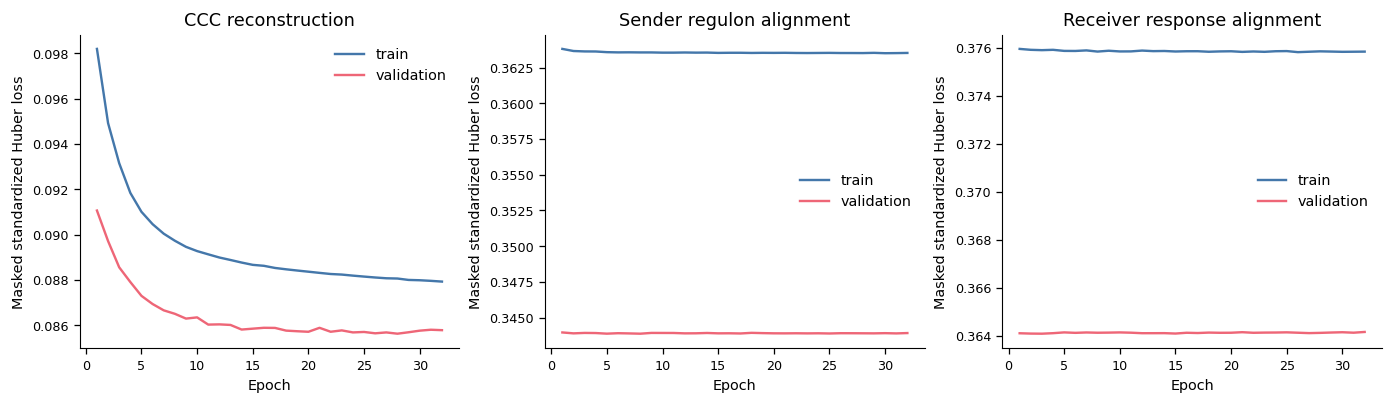

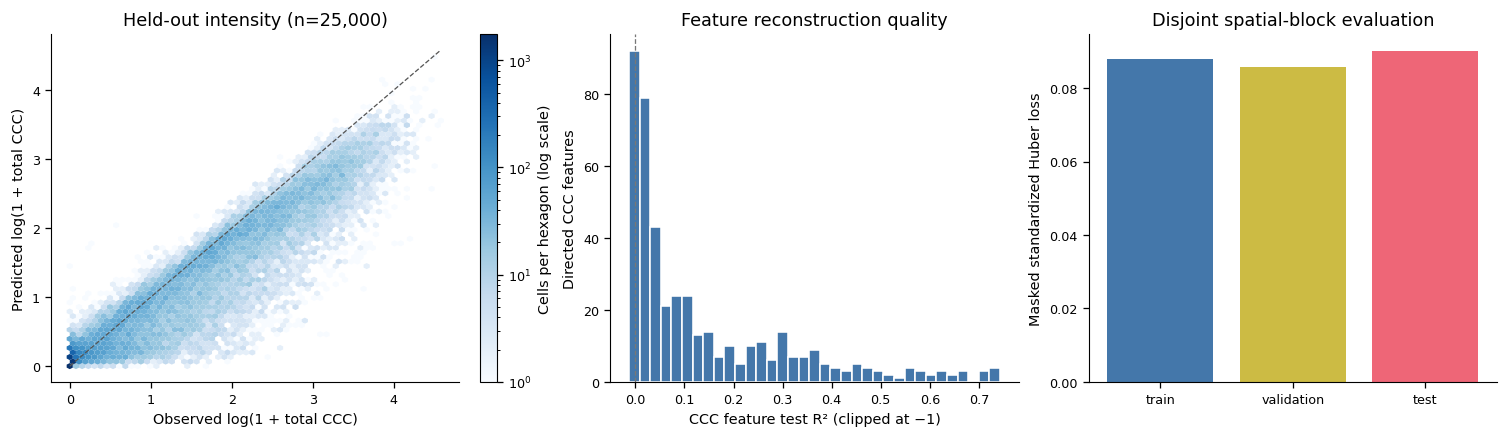

,n,scaled_huber,native_RMSE,median_feature_R2
train,359883.0,0.087973,0.083350,0.070544
validation,107313.0,0.085646,0.081066,0.056855
test,112368.0,0.090156,0.088330,0.059171


,Held-out metrics
best_epoch,26
validation_loss,0.157702
test,"{'ccc': 0.09015562224702993, 'regularization': 0.25063952340430284, 'upstream': 0.3620673805521914, 'downstream': 0.36574690085725026, 'total': 0...."


In [3]:
show(report.training_curves())
show(report.reconstruction())
display(pd.DataFrame(report.reconstruction_metrics).T)
display(pd.Series(json.loads((OUTPUT/'heldout_metrics.json').read_text())).to_frame('Held-out metrics'))

## 3. Usage and directed CCC interpretation of all 32 programs

H entries trace programs to specific sender → receiver → ligand–receptor features. Absolute Z retains intensity; relative mixture preserves composition. Prior-linked regulators and targets are hypotheses supported by the supplied databases; NicheNet response modules do not establish receptor-specific causal effects.

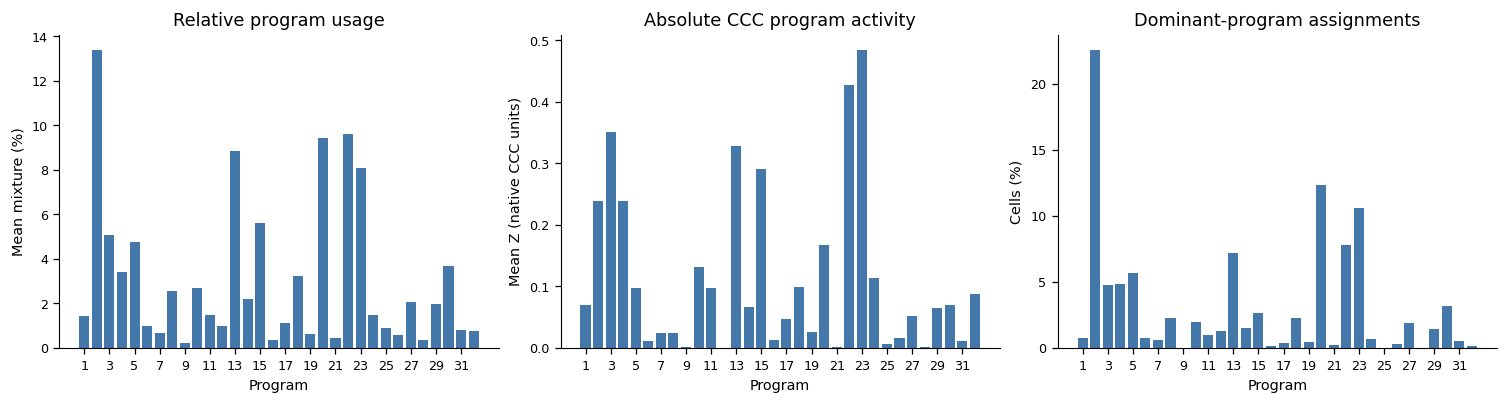

,program,mean_mixture,mean_exposure,dominant_fraction
0,1,0.014341,0.069578,0.007404
1,2,0.134075,0.238273,0.225713
2,3,0.050929,0.350919,0.047257
3,4,0.034104,0.239320,0.048005
4,5,0.047819,0.097414,0.056771
5,6,0.009670,0.011478,0.007201
6,7,0.006572,0.024433,0.006103
7,8,0.025464,0.024566,0.022437
8,9,0.002322,0.002194,0.000000
9,10,0.026772,0.132333,0.019412


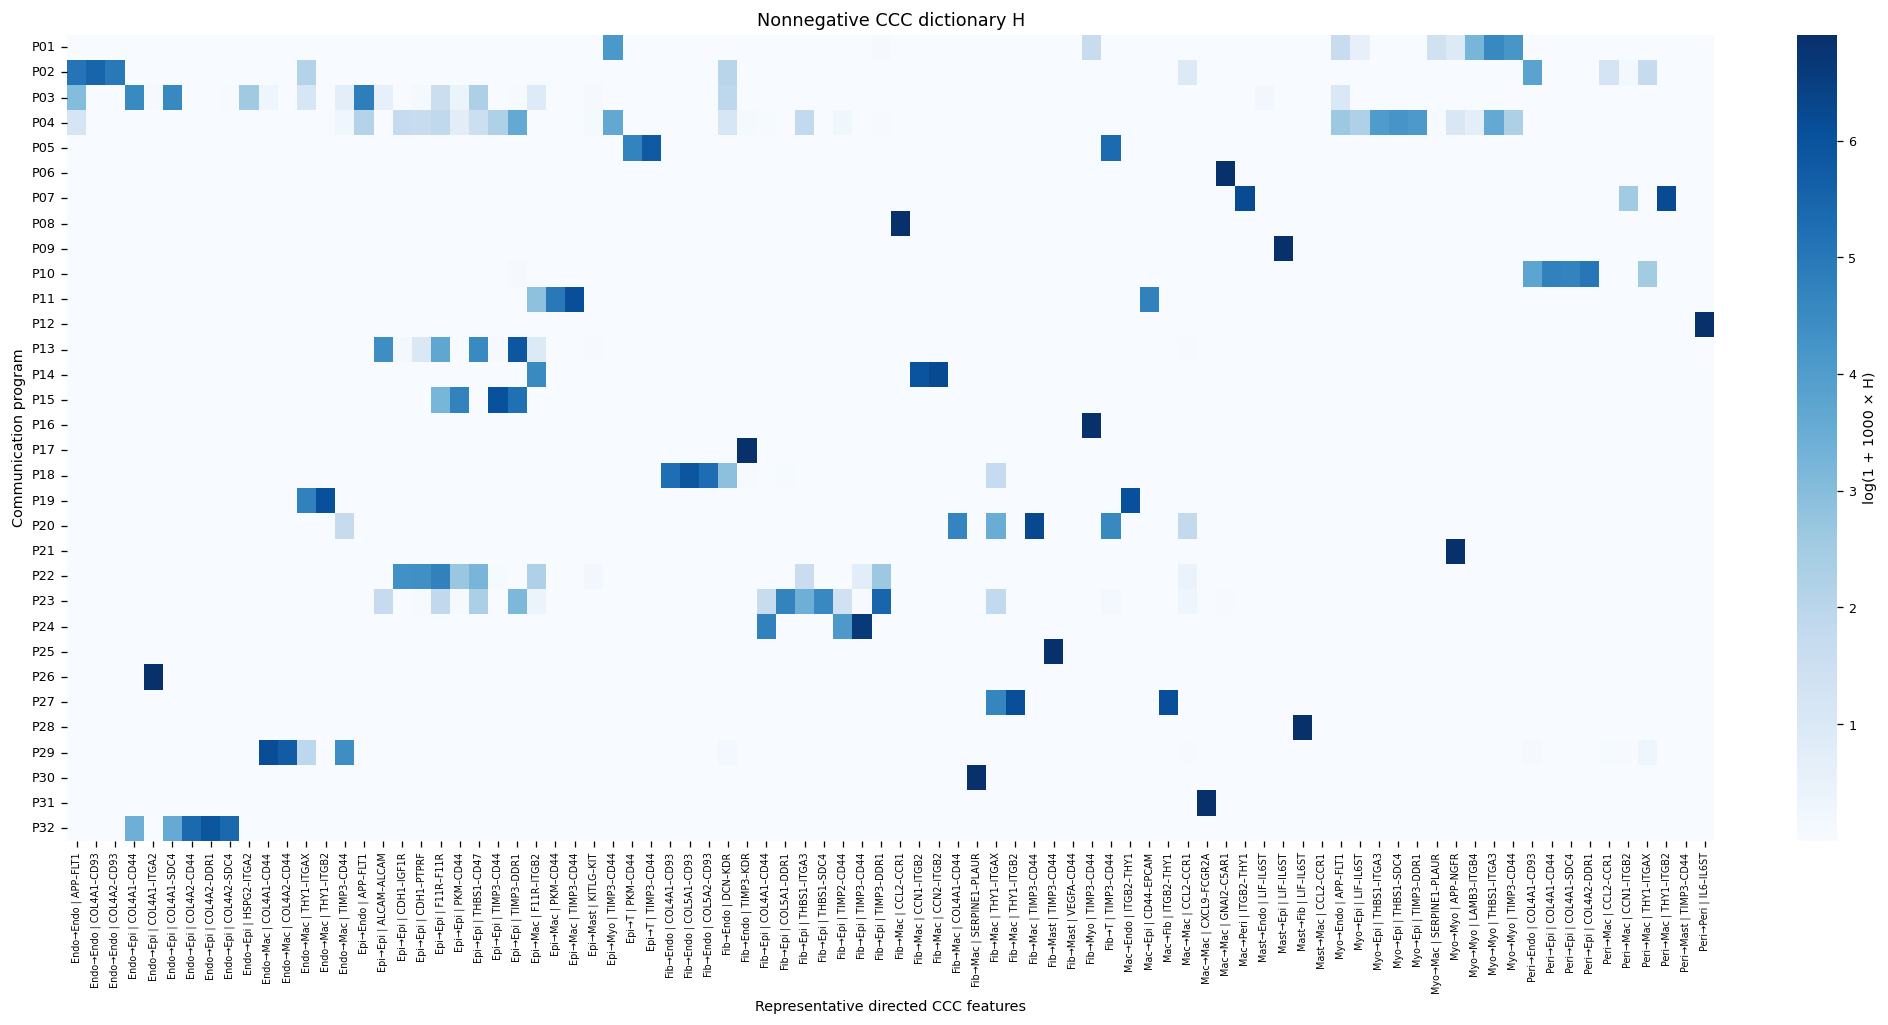

,program,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,370,Myoepithelial → Myoepithelial | THBS1–ITGA3,Myoepithelial,Myoepithelial,THBS1,ITGA3,9.676127e-02
1,1,2,372,Myoepithelial → Myoepithelial | TIMP3–CD44,Myoepithelial,Myoepithelial,TIMP3,CD44,6.489915e-02
2,1,3,155,Epithelial → Myoepithelial | TIMP3–CD44,Epithelial,Myoepithelial,TIMP3,CD44,5.957377e-02
3,1,4,375,Myoepithelial → Myoepithelial | TNC–ITGA2,Myoepithelial,Myoepithelial,TNC,ITGA2,5.761205e-02
4,1,5,376,Myoepithelial → Myoepithelial | TNC–ITGB6,Myoepithelial,Myoepithelial,TNC,ITGB6,5.664735e-02
15,2,1,2,Endothelial → Endothelial | COL4A1–CD93,Endothelial,Endothelial,COL4A1,CD93,2.404269e-01
16,2,2,0,Endothelial → Endothelial | APP–FLT1,Endothelial,Endothelial,APP,FLT1,1.623152e-01
17,2,3,3,Endothelial → Endothelial | COL4A2–CD93,Endothelial,Endothelial,COL4A2,CD93,1.438993e-01
18,2,4,387,Pericyte → Endothelial | COL4A1–CD93,Pericyte,Endothelial,COL4A1,CD93,4.459964e-02
19,2,5,176,Fibroblast → Endothelial | TIMP3–ADAMTS4,Fibroblast,Endothelial,TIMP3,ADAMTS4,2.697471e-02


,program,module,cell_type,entity,entity_on_panel,targets_on_panel,target_coverage,targets,sources,evidence,communication_link_evidence,interpretation,prior_loading
0,1,Myoepithelial|CEBPZ,Myoepithelial,CEBPZ,False,14,0.777778,ALOX12;APC;CDKN1A;COL10A1;COL11A1;CP;CYBB;FAS;GZMB;HSPA4;IL3;MLH1;SOX9;TP73,CollecTRI2;ExTRI2_CollecTRI2;GOA_CollecTRI2;GOA_CollecTRI;CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;ExTRI_CollecTRI;CollecT...,CollecTRI2:10933728;CollecTRI:10933728;CollecTRI2:9628332;CollecTRI2:8418500;CollecTRI2:9498488;CollecTRI2:10687862;CollecTRI2:1534142;CollecTRI:2...,CollecTRI:18275041;CollecTRI2:18275041;DoRothEA:18275041;HTRIdb:18275041,TF regulon proxy,0.020707
1,1,Myoepithelial|DMTF1,Myoepithelial,DMTF1,False,7,0.388889,ADM;ANPEP;BCL3;CDKN1A;CDKN2A;KRAS;NES,ExTRI_CollecTRI;CollecTRI;NTNUcuration_CollecTRI2;CollecTRI2;ExTRI2_CollecTRI2;NTNU.Curated_CollecTRI;ExTRI_CollecTRI;CollecTRI;SIGNOR_CollecTRI2;...,CollecTRI2:22039255;CollecTRI:22039255;CollecTRI2:26187004;CollecTRI:22039255;CollecTRI:10097151;CollecTRI2:15601844;CollecTRI2:21062982;CollecTRI...,CollecTRI:19816943;SIGNOR:19816943;CollecTRI2:19816943,TF regulon proxy,0.020707
2,1,Myoepithelial|PAX5,Myoepithelial,PAX5,True,43,0.741379,ABL1;AICDA;BAX;BCL2;BCR;BLNK;CCND1;CD19;CD72;CD79A;CDKN1A;CR1;CR2;CSF1R;EBF1;FCER2;FDPS;FHL2;GADD45A;GSTM1;IGHE;IL2;IL7;MET;MPPED2;MYCN;NCAM1;NEDD...,ARACNe-GTEx_DoRothEA;ReMap_DoRothEA;TRRUST;CollecTRI2;DoRothEA;ENCODE-distal;ExTRI2_CollecTRI2;TRRUST_DoRothEA;TRRUST_CollecTRI;CollecTRI;TfactS_C...,CollecTRI2:10197586;DoRothEA:10197586;TRRUST:10197586;CollecTRI:10197586;CollecTRI2:10934015;CollecTRI:10934015;CollecTRI2:11179673;CollecTRI:1117...,CollecTRI:23438850,TF regulon proxy,0.020707
15,2,Endothelial|LEF1,Endothelial,LEF1,True,67,0.644231,AR;AXIN1;BCL2;BIRC5;BMP4;CACNA1G;CCNA1;CCND1;CD1D;CD4;CDKN1A;CDKN2A;CDX1;COL2A1;CTNNAL1;CTNNB1;CXCR4;CYLD;DCT;DLL1;E2F1;EDA;ELANE;FAIM2;FASLG;FGF4...,ARACNe-GTEx_DoRothEA;NTNUcuration_CollecTRI2;CollecTRI2;DoRothEA;ExTRI2_CollecTRI2;NTNU.Curated_CollecTRI;TFactS_CollecTRI;RegNetwork_DoRothEA;ExT...,CollecTRI2:11696550;CollecTRI:11696550;CollecTRI2:11935128;CollecTRI:11935128;CollecTRI2:12244173;CollecTRI:12244173;CollecTRI2:12244173;CollecTRI...,DoRothEA:15979100;CollecTRI2:15979100;CollecTRI:15979100,TF regulon proxy,-0.040580
16,2,Endothelial|KAT7,Endothelial,KAT7,False,50,0.632911,APC;BIRC3;BTK;CARM1;CCNA2;CCND1;CCNE1;CD4;CDKN1A;CDKN1B;CFTR;COMT;CREBBP;CSF2;CYP24A1;DRD2;GCM1;GSK3B;HMOX1;IL12B;IL1B;IL2;IL4;IL5;ITPR1;KAT2A;KAT...,ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;ExTRI_CollecTRI;CollecTRI,CollecTRI2:23524580;CollecTRI:23524580;CollecTRI2:26625199;CollecTRI:12609999;CollecTRI:22713239;CollecTRI:20123734;CollecTRI:10075672;CollecTRI:1...,CollecTRI:16332686,TF regulon proxy,0.040580
17,2,Endothelial|NCOR2,Endothelial,NCOR2,True,23,0.575000,ACHE;AKT1;BCOR;CCND1;CCR4;CHEK2;CREBBP;EBP;FOLR1;IL1B;LPL;MYCN;NR0B1;NRIP1;POU2AF1;PPARD;PPARG;PPARGC1A;RUNX1T1;SIN3A;TH;TNF;TRH,CollecTRI2;ExTRI2_CollecTRI2;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;ExTRI_CollecTRI;C...,CollecTRI2:10098492;CollecTRI:10098492;CollecTRI2:15001550;CollecTRI:15001550;CollecTRI2:23690919;CollecTRI:23690919;CollecTRI2:9827656;CollecTRI:...,CollecTRI:16219912,TF regulon proxy,0.040580
30,3,Epithelial|NCOR2,Epithelial,NCOR2,True,23,0.575000,ACHE;AKT1;BCOR;CCND1;CCR4;CHEK2;CREBBP;EBP;FOLR1;IL1B;LPL;MYCN;NR0B1;NRIP1;POU2AF1;PPARD;PPARG;PPARGC1A;RUNX1T1;SIN3A;TH;TNF;TRH,CollecTRI2;ExTRI2_CollecTRI2;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;ExTRI_CollecTRI;C...,CollecTRI2:10098492;CollecTRI:10098492;CollecTRI2:15001550;CollecTRI:15001550;CollecTRI2:23690919;CollecTRI:23690919;CollecTRI2:9827656;CollecTRI:...,CollecTRI:16219912,TF regulon proxy,0.032734
31,3,Epithelial|HDAC9,Epithelial,HDAC9,True,12,0.857143,DIRAS3;IGFBP1;LPL;MEF2A;MMP13;MYEF2;NFKB1;PRL;RELA;STAT6;TNFRSF10B;TP53,Co

,program,module,cell_type,entity,entity_on_panel,targets_on_panel,target_coverage,targets,sources,evidence,communication_link_evidence,interpretation,prior_loading
0,1,Myoepithelial|LAMB3,Myoepithelial,LAMB3,True,59,0.655556,ADM;AR;ATF3;BAX;BCL2;BCL2L1;BCL6;BIRC3;BIRC5;BRCA1;CCDC9;CCNA2;CCND1;CCND2;CDK6;CDKN1A;CSF2;CXCR4;CYP1B1;DDIT3;DKK1;DUSP6;EBI3;EDN1;EGFR;FAS;GADD4...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,3.023504e-02
1,1,Myoepithelial|COL17A1,Myoepithelial,COL17A1,True,46,0.505495,ATF3;BAX;BCL2;BCL2L1;BCL6;BIRC5;BRCA1;CCND1;CCND2;CCR3;CCR6;CDKN1A;COL10A1;CXCR4;CYP1B1;DKK1;DUSP6;EDN1;ENPP2;FAS;GABRA2;GADD45A;GDF15;HES1;HMOX1;...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,2.424898e-02
2,1,Myoepithelial|TNC,Myoepithelial,TNC,True,58,0.651685,ADM;AR;ATF3;BCL2;BCL2L1;BCL6;BIRC5;BRCA1;CCNA2;CCND1;CCND2;CDKN1A;CLDN1;CSF2;CTNNB1;CXCR4;CYP1B1;DDIT3;DKK1;DUSP6;EDN1;EDNRA;EGFR;FAS;FOSL1;FST;GA...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,2.212264e-02
15,2,Endothelial|COL4A1,Endothelial,COL4A1,True,40,0.449438,ATF3;BAX;BCL2;BCL2L1;BCL6;BIRC5;BRCA1;CCND1;CCND2;CCR3;CCR6;CDC25C;CDKN1A;CHRNA4;COL10A1;CXCR4;DKK1;EDN1;ENPP2;FAS;GADD45A;GDF15;HMOX1;ICAM1;IFNG;...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,7.125721e-02
16,2,Endothelial|COL4A2,Endothelial,COL4A2,True,51,0.566667,ATF3;AVPR1B;BAX;BCL2;BCL2L1;BCL6;BIRC5;BRCA1;CCNA2;CCND1;CCND2;CDK6;CDKN1A;CXCR4;CYP1B1;DDIT3;DKK1;DUSP6;EDN1;EGFR;EYA1;FAS;FOSL1;GADD45A;GDF15;HE...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,3.756277e-02
17,2,Endothelial|APP,Endothelial,APP,True,52,0.553191,ACKR3;ADAM17;ANGPTL4;APCDD1;BACE1;BAX;BCL2;BDNF;BMP7;CBLN4;CCL18;CCN4;CCR5;CD40;CD83;CDKN1A;CDX1;CSF1R;DDIT3;DIO2;DUOX2;DUSP5;EGR2;EGR3;FABP3;FHL1...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,3.455612e-02
30,3,Endothelial|VEGFB,Endothelial,VEGFB,True,53,0.576087,ATF3;BAX;BCL2;BCL2L1;BCL6;BIRC5;BRCA1;CCNA2;CCND1;CCND2;CCND3;CDKN1A;CXCR4;CYP1B1;DDIT3;DKK1;DUSP5;DUSP6;EDN1;EGR3;FAS;FASN;GADD45A;GDF15;HIF1A;HM...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,3.572259e-02
31,3,Endothelial|APP,Endothelial,APP,True,52,0.553191,ACKR3;ADAM17;ANGPTL4;APCDD1;BACE1;BAX;BCL2;BDNF;BMP7;CBLN4;CCL18;CCN4;CCR5;CD40;CD83;CDKN1A;CDX1;CSF1R;DDIT3;DIO2;DUOX2;DUSP5;EGR2;EGR3;FABP3;FHL1...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,3.172724e-02
32,3,Endothelial|CALM3,Endothelial,CALM3,True,45,0.489130,ATF3;BAX;BCL2;BCL2L1;BCL6;BRCA1;CBLB;CCND1;CCR6;CDK6;CDKN1A;COL10A1;CSF2;DDIT3;DEFA6;DUSP6;EDN1;EGFR;ENPP2;FAS;GADD45A;GDF15;HMOX1;ICAM1;IFNG;IL10...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-066

In [4]:
fig,usage=report.program_usage();show(fig);display(usage)
show(report.dictionary_heatmap())
display(pd.read_csv(OUTPUT/'programs/top_ccc.csv').groupby('program').head(5))
for branch in ('upstream','downstream'):
    display(pd.read_csv(OUTPUT/'programs'/f'{branch}.csv').groupby('program').head(3))

## 4. Automatic niche selection, K = 4–15

Clustering uses communication mixture and a weighted log-activity component of Z. K is selected on validation blocks using silhouette, clustering-seed stability, and niche balance; test blocks are not used for K selection. Stability here concerns clustering seeds, not independent GNN training seeds.

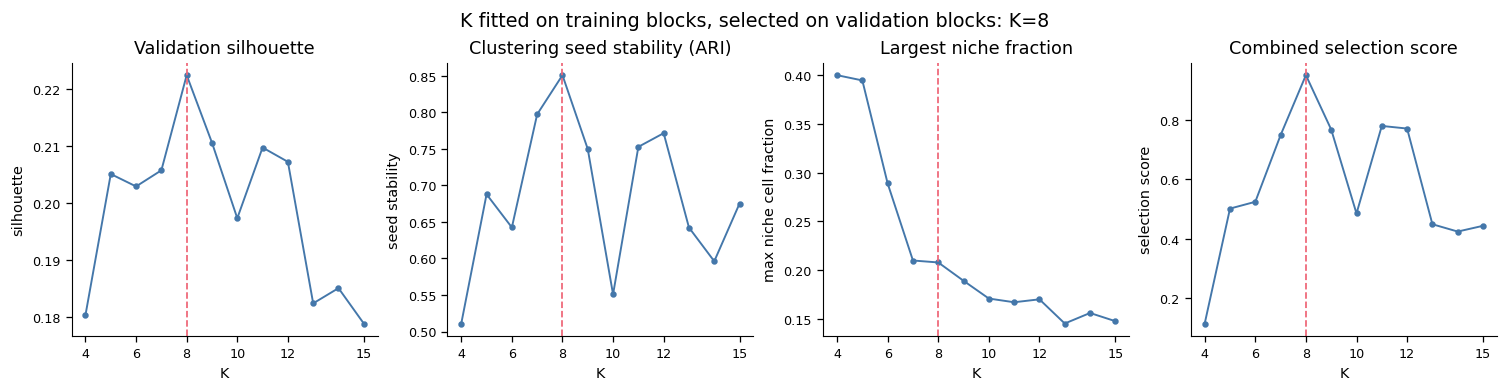

,K,silhouette,seed_stability,max_niche_cell_fraction,tiny_niche_fraction,active_niches,selection_score,eligible,selected
0,4,0.180430,0.510957,0.4000,0.0,4,0.113775,True,False
1,5,0.205161,0.687841,0.3946,0.0,5,0.501146,True,False
2,6,0.202981,0.642446,0.2890,0.0,6,0.524028,True,False
3,7,0.205812,0.797313,0.2100,0.0,7,0.748753,True,False
4,8,0.222504,0.850879,0.2080,0.0,8,0.950825,True,True
5,9,0.210655,0.749773,0.1892,0.0,9,0.767593,True,False
6,10,0.197403,0.550860,0.1710,0.0,10,0.484683,True,False
7,11,0.209805,0.752777,0.1672,0.0,11,0.779724,True,False
8,12,0.207303,0.771487,0.1702,0.0,12,0.770905,True,False
9,13,0.182466,0.642308,0.1454,0.0,13,0.448386,True,False


In [5]:
show(report.k_selection())
display(report.selection)

## 5. Cell types and communication niches in tissue space

All cell centers are plotted in original micrometers; no spatial region or phenotype labels are supplied to the model.

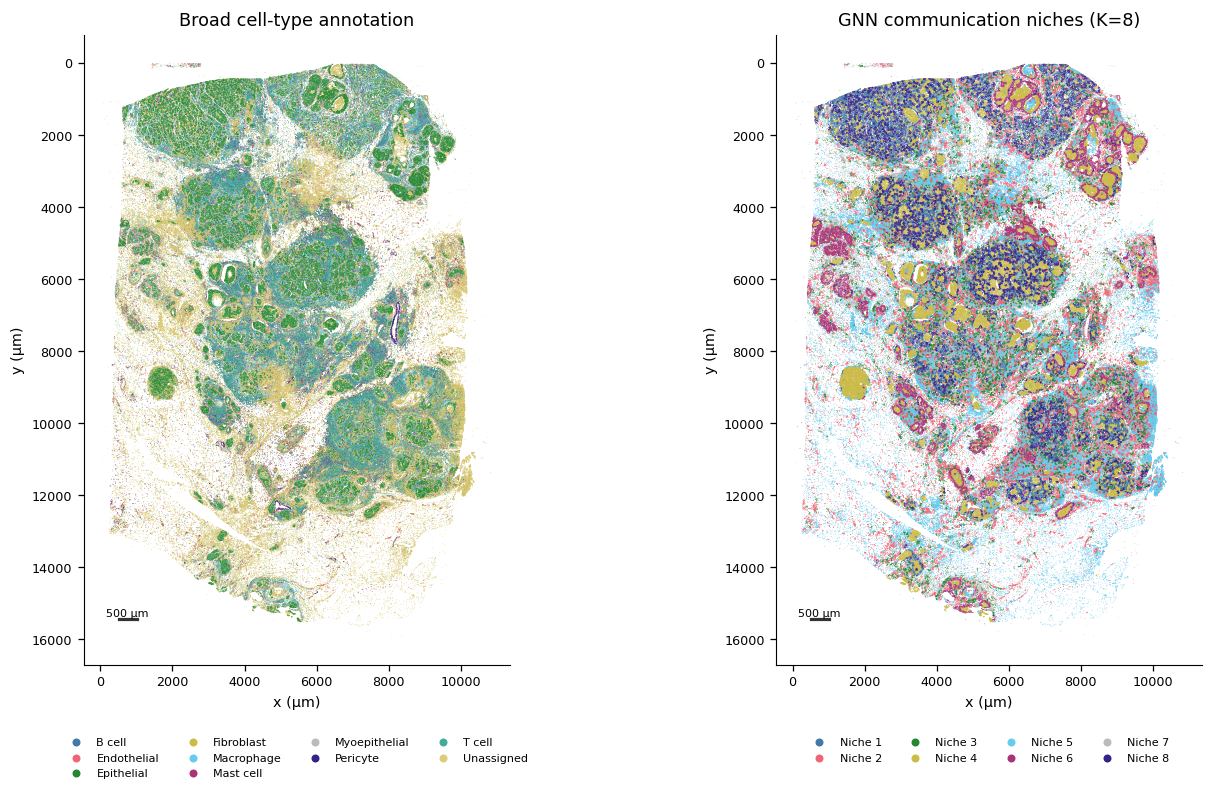

In [6]:
show(report.spatial_overview())

## 6. Individual niches, cell-type composition, and enrichment

Enrichment is descriptive log₂ fold enrichment against this tissue, without independent-cell p-values. Both center-cell labels and the original physical-neighborhood composition are displayed.

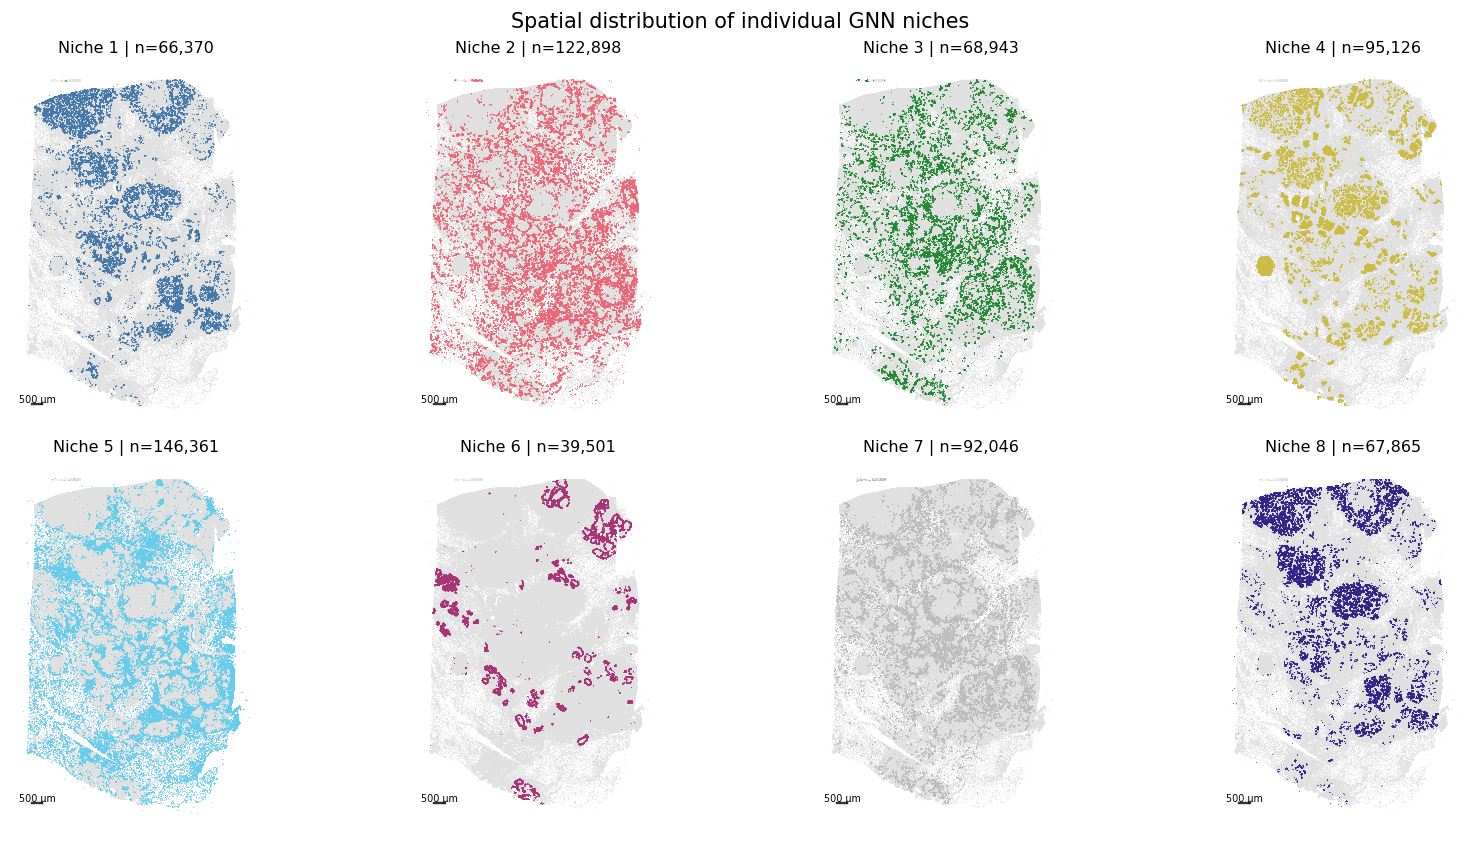

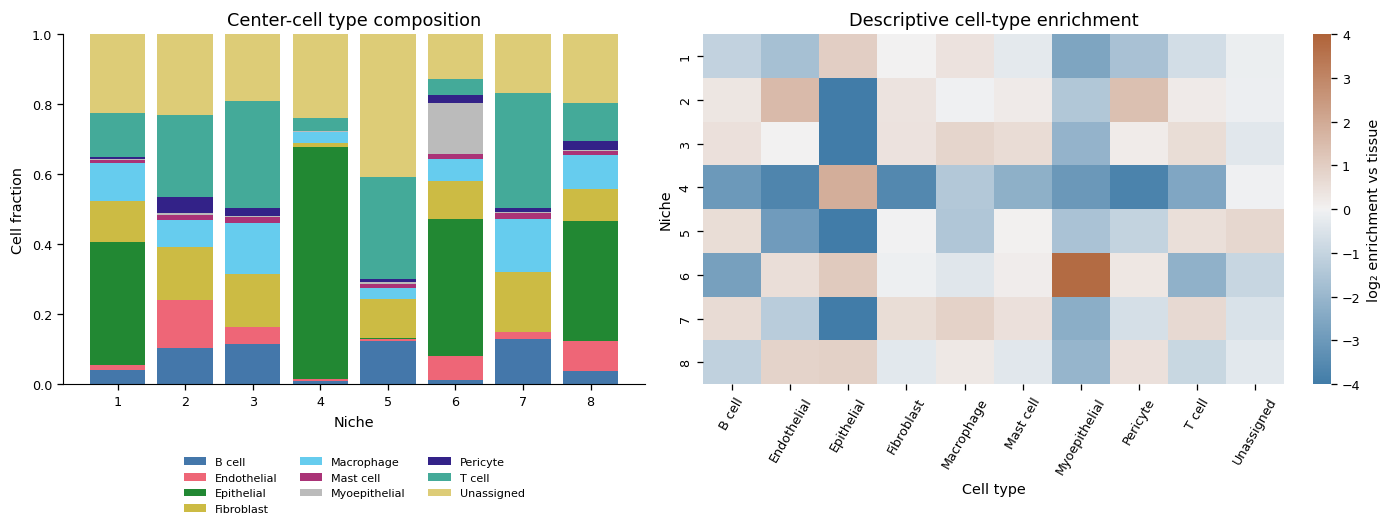

cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,0.039250,0.014208,0.353654,0.115414,0.108724,0.010396,0.001778,0.005861,0.125780,0.224936
2,0.104623,0.135259,0.001058,0.149823,0.078952,0.014508,0.003922,0.047332,0.234398,0.230126
3,0.115849,0.046415,0.001465,0.152488,0.143582,0.019320,0.002495,0.020481,0.306761,0.191143
4,0.010302,0.003585,0.665244,0.009524,0.030654,0.002681,0.001304,0.001335,0.035322,0.240050
5,0.124275,0.006019,0.002022,0.112530,0.029325,0.013132,0.003546,0.008807,0.291512,0.408832
6,0.012076,0.067669,0.392977,0.107947,0.063011,0.013822,0.146401,0.022455,0.045037,0.128604
7,0.129609,0.019099,0.001184,0.169307,0.152630,0.017806,0.002205,0.011777,0.328901,0.167481
8,0.038503,0.083651,0.344994,0.091034,0.097694,0.009946,0.002623,0.025624,0.109217,0.196714


cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,-1.070754,-1.692006,0.968773,0.012549,0.410319,-0.282763,-2.607554,-1.636821,-0.709518,-0.136890
2,0.343675,1.558825,-7.415011,0.388996,-0.051302,0.197977,-1.466610,1.376538,0.188535,-0.103982
3,0.490719,0.015793,-6.945561,0.414431,0.811527,0.611225,-2.119038,0.168029,0.576689,-0.371748
4,-3.000389,-3.678499,1.880318,-3.586382,-1.416164,-2.237772,-3.055014,-3.770237,-2.541767,-0.043070
5,0.592003,-2.930911,-6.480645,-0.023955,-1.480122,0.054220,-1.611939,-1.049421,0.503131,0.725099
6,-2.771252,0.559687,1.120882,-0.083945,-0.376662,0.128149,3.755246,0.300803,-2.191220,-0.943460
7,0.652635,-1.265250,-7.252305,0.565370,0.899688,0.493503,-2.296842,-0.630246,0.677228,-0.562401
8,-1.098466,0.865573,0.933006,-0.329789,0.255994,-0.346603,-2.046862,0.491269,-0.913221,-0.330303


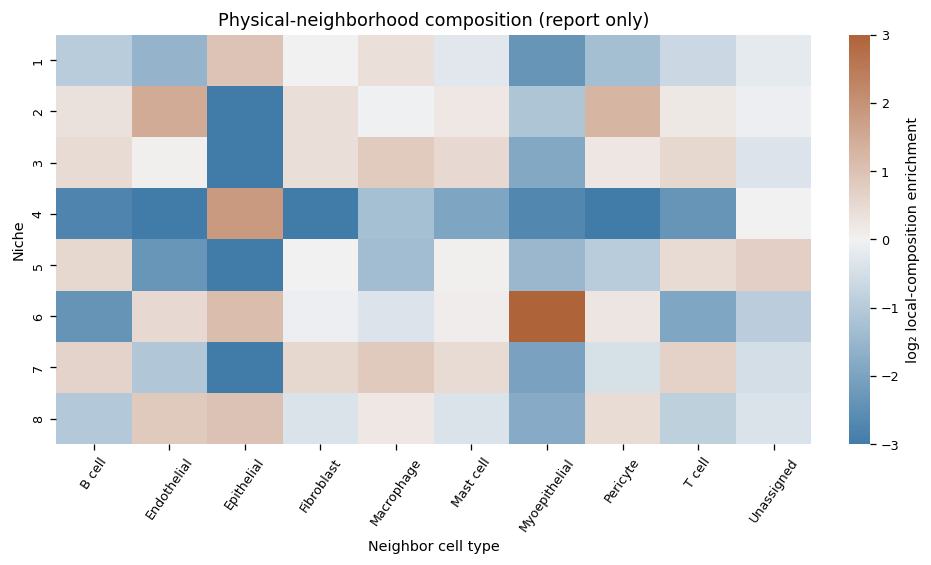

In [7]:
show(report.each_niche())
fig,fraction,enrichment=report.composition();show(fig)
display(fraction)
display(enrichment)
show(report.local_composition())

## 7. Niche × CCC program activity

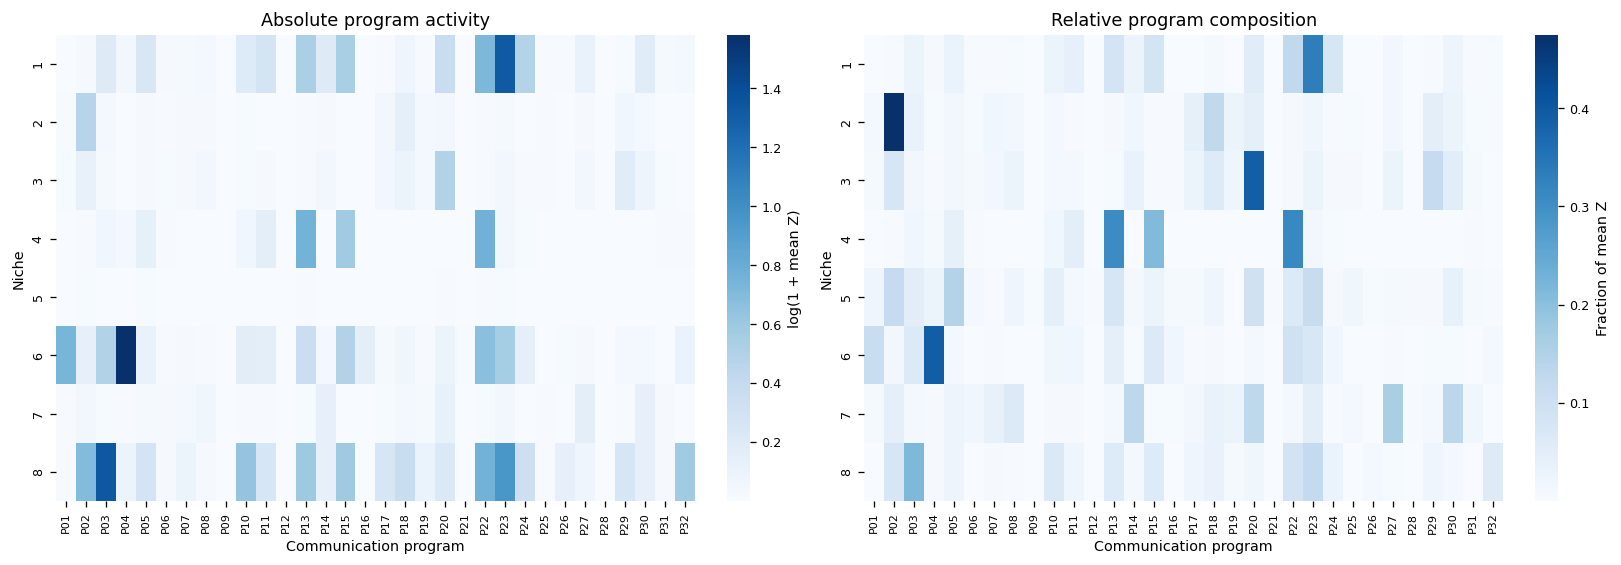

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,...,P23,P24,P25,P26,P27,P28,P29,P30,P31,P32
1,0.002460,0.022503,0.218966,0.049699,0.273708,0.023773,0.025162,0.036350,0.006191,0.227430,...,2.764304,0.634166,0.010984,0.009643,0.124006,0.001178,0.018491,0.202912,0.025705,0.035492
2,0.014448,0.607217,0.043397,0.006189,0.019354,0.006370,0.023665,0.020055,0.000852,0.014286,...,0.025666,0.003853,0.006815,0.000949,0.020326,0.002133,0.063188,0.033557,0.004989,0.004689
3,0.013220,0.127154,0.025708,0.005883,0.024607,0.014574,0.024768,0.047865,0.001162,0.015801,...,0.046825,0.010902,0.011391,0.000436,0.049123,0.003023,0.199983,0.087718,0.014985,0.002797
4,0.000791,0.007462,0.063171,0.031867,0.150768,0.009651,0.002802,0.001036,0.002036,0.063592,...,0.056633,0.017739,0.000800,0.002377,0.002000,0.000126,0.000957,0.003536,0.007937,0.006311
5,0.002446,0.014379,0.006107,0.003155,0.017324,0.001212,0.000443,0.002835,0.000589,0.005518,...,0.013703,0.000882,0.002339,0.000595,0.000958,0.000766,0.000756,0.004450,0.000983,0.000280
6,1.112013,0.140979,0.643801,3.865713,0.118116,0.006380,0.019023,0.010177,0.003367,0.186930,...,0.747587,0.165644,0.005037,0.014437,0.024621,0.001129,0.039669,0.037886,0.003057,0.115038
7,0.009377,0.048468,0.012972,0.007157,0.026962,0.020834,0.038666,0.069450,0.001476,0.007400,...,0.052047,0.003749,0.011627,0.000432,0.168636,0.003236,0.010662,0.142252,0.020372,0.000803
8,0.009703,1.016331,2.807509,0.095289,0.322413,0.020604,0.091066,0.025051,0.005740,0.882191,...,1.594832,0.412946,0.009050,0.142246,0.072679,0.001263,0.296959,0.141989,0.021229,0.788438


In [8]:
fig,activities=report.niche_programs();show(fig);display(activities)

## 8. Representative CCC, upstream regulators, and downstream targets

[CollecTRI](https://github.com/saezlab/CollecTRI) signed TF–ligand priors connect sender regulon proxies to H. [NicheNet-v2](https://zenodo.org/records/7074291) connects ligands to measured receiver target modules. Source URLs, raw-file checksums, and panel/feature matching are retained in the audit and prior manifest. Activities use exactly the original directed physical pairs and spatial weighting. Niche CCC/prior profiles use training-block soft program contributions; the activity heatmaps above use mean Z of assigned cells. Prior dictionary loadings below indicate communication-linked support, rather than differential TF activity or proof of signaling. Calibration-valid flags and evidence are available in the complete CSVs. No patient phenotypes are inferred.

Held-out biological residual R²: upstream 0.0011, downstream 0.0008.
Regulatory predictive signal is very weak. These prior-linked annotations do not validate signaling mechanisms or establish benefit from biological losses; training ablations are still needed.


,niche,cells,leading_programs,representative_CCC,upstream,downstream,response_targets
0,1,66370,"P23, P22, P13",Fibroblast → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–DDR1; Fibroblast → Epithelial | TIMP3–CD44,Fibroblast: BARX2; Fibroblast: ELF3; Fibroblast: FOXN1,Epithelial: TIMP3; Epithelial: COL5A1; Macrophage: CCN2,"ADM, ATF3, BCL2, BCL2L1, BCL2L11, BCL6, BIRC3, BIRC5; AP3B2, BCL2, BCL2L1, CAPN1, CCL27, CCND1, CCR3, CCR6; ABCB6, ABCD3, ADIPOR1, ATF3, BAX, BCL2..."
1,2,122898,"P02, P18, P20",Endothelial → Endothelial | COL4A1–CD93; Endothelial → Endothelial | APP–FLT1; Endothelial → Endothelial | COL4A2–CD93,Endothelial: TFAP4; Endothelial: TBP; Endothelial: KAT7,Endothelial: COL5A1; Endothelial: COL4A1; Endothelial: COL5A2,"AP3B2, BCL2, BCL2L1, CAPN1, CCL27, CCND1, CCR3, CCR6; ATF3, BAX, BCL2, BCL2L1, BCL6, BIRC5, BRCA1, CCND1; ATF3, BCAR3, BCL2, BCL2L1, BCL6, BIRC5, ..."
2,3,68943,"P20, P02, P29",Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → Macrophage | SERPINE1–PLAUR; Endothelial → Macrophage | COL4A1–CD44,Fibroblast: ZNF354C; Fibroblast: ATF2; Fibroblast: IRF1,Macrophage: TIMP3; Macrophage: CCN2; Endothelial: COL5A1,"ADM, ATF3, BCL2, BCL2L1, BCL2L11, BCL6, BIRC3, BIRC5; ABCB6, ABCD3, ADIPOR1, ATF3, BAX, BCL2, BCL2L1, BCL6; AP3B2, BCL2, BCL2L1, CAPN1, CCL27, CCN..."
3,4,95126,"P22, P13, P15",Epithelial → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44; Epithelial → Epithelial | F11R–F11R,Epithelial: BARX2; Epithelial: ELF3; Epithelial: SRF,Epithelial: F11R; Epithelial: TIMP3; Epithelial: ALCAM,"ADM, ATF3, BAX, BCL2, BCL2L1, BCL6, BIRC5, BRCA1; ADM, ATF3, BCL2, BCL2L1, BCL2L11, BCL6, BIRC3, BIRC5; AIM2, BCL2, CASP6, CCND1, CD244, CDKN1A, D..."
4,5,146361,"P02, P23, P22",Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → Macrophage | SERPINE1–PLAUR; Epithelial → Epithelial | TIMP3–DDR1,Fibroblast: ZNF354C; Fibroblast: ATF2; Fibroblast: APEX1,Endothelial: COL5A1; Macrophage: SERPINE1; Macrophage: CCN2,"AP3B2, BCL2, BCL2L1, CAPN1, CCL27, CCND1, CCR3, CCR6; ATF3, BCL2, BCL2L1, BCL6, BDNF, BIRC3, BIRC5, BRCA1; ABCB6, ABCD3, ADIPOR1, ATF3, BAX, BCL2,..."
5,6,39501,"P04, P22, P01",Epithelial → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44; Fibroblast → Epithelial | TIMP3–DDR1,Myoepithelial: DMTF1; Myoepithelial: ID3; Myoepithelial: CEBPZ,Epithelial: TIMP3; Epithelial: F11R; Epithelial: CDH1,"ADM, ATF3, BCL2, BCL2L1, BCL2L11, BCL6, BIRC3, BIRC5; ADM, ATF3, BAX, BCL2, BCL2L1, BCL6, BIRC5, BRCA1; ATF3, BCL2, BCL2L1, BCL6, BIRC5, BMP4, BRC..."
6,7,92046,"P20, P27, P23",Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → Macrophage | SERPINE1–PLAUR; Fibroblast → Macrophage | CCN2–ITGB2,Fibroblast: FOXC1; Fibroblast: MZF1; Fibroblast: MAF,Macrophage: CCN2; Fibroblast: ITGB2; Macrophage: SERPINE1,"ABCB6, ABCD3, ADIPOR1, ATF3, BAX, BCL2, BCL2L1, BCL6; ATF3, BARX2, BAX, BCL2, BCL2L1, BCL6, BIRC3, BIRC5; ATF3, BCL2, BCL2L1, BCL6, BDNF, BIRC3, B..."
7,8,67865,"P03, P23, P22",Epithelial → Epithelial | TIMP3–DDR1; Fibroblast → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44,Fibroblast: FOXN1; Fibroblast: ELF3; Fibroblast: BARX2,Epithelial: TIMP3; Endothelial: COL5A1; Epithelial: COL5A1,"ADM, ATF3, BCL2, BCL2L1, BCL2L11, BCL6, BIRC3, BIRC5; AP3B2, BCL2, BCL2L1, CAPN1, CCL27, CCND1, CCR3, CCR6; AP3B2, BCL2, BCL2L1, CAPN1, CCL27, CCN..."


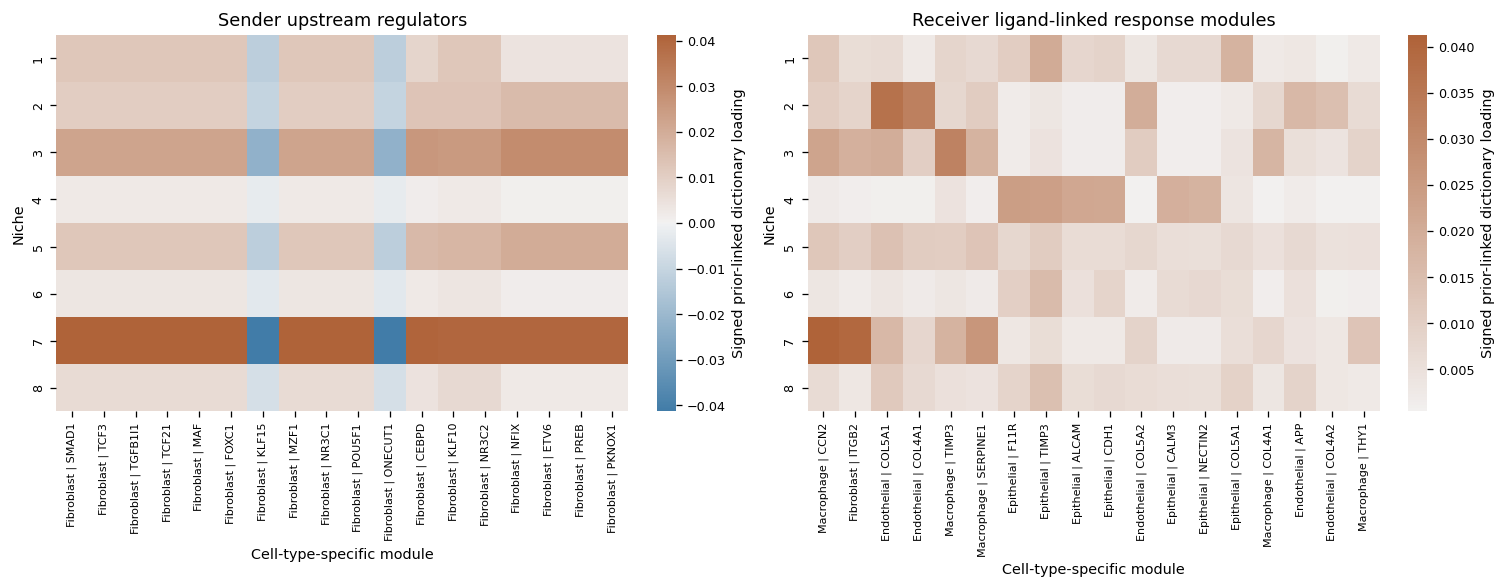

Niche 1
CCC


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,204,Fibroblast → Epithelial | TIMP3–DDR1,Fibroblast,Epithelial,TIMP3,DDR1,0.067563
1,1,2,116,Epithelial → Epithelial | TIMP3–DDR1,Epithelial,Epithelial,TIMP3,DDR1,0.050102
2,1,3,203,Fibroblast → Epithelial | TIMP3–CD44,Fibroblast,Epithelial,TIMP3,CD44,0.047097
3,1,4,115,Epithelial → Epithelial | TIMP3–CD44,Epithelial,Epithelial,TIMP3,CD44,0.033900
4,1,5,191,Fibroblast → Epithelial | COL5A1–DDR1,Fibroblast,Epithelial,COL5A1,DDR1,0.029867


upstream


,niche,module,cell_type,entity,entity_on_panel,targets_on_panel,target_coverage,targets,sources,evidence,communication_link_evidence,interpretation,prior_loading,used_in_bio_loss,training_residual_slope
0,1,Fibroblast|BARX2,Fibroblast,BARX2,True,9,0.750000,CCND1;CDH6;HSPA9;L1CAM;MMP9;MYOD1;RBM15;SMN2;SOX5,CollecTRI2;ExTRI2_CollecTRI2;ExTRI_CollecTRI;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;CollecTRI2;ExTRI2_CollecTRI2;GEREDB_CollecTRI2;CollecTRI...,CollecTRI2:11585719;CollecTRI:15034005;CollecTRI2:15034005;CollecTRI:11585719;CollecTRI2:12486129;CollecTRI2:19269978;CollecTRI:19269978;CollecTRI...,CollecTRI:16636675;CollecTRI2:16636675,TF regulon proxy,0.014707,True,0.018424
1,1,Fibroblast|ELF3,Fibroblast,ELF3,False,14,0.518519,ANGPT1;CCL20;CCND3;EHF;ERBB2;FOLH1;IL1B;MMP13;MMP9;NOS2;POU5F1;PTGS2;SPRR3;TGFB1,CollecTRI2;ExTRI2_CollecTRI2;ExTRI_CollecTRI;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;E...,CollecTRI2:10506207;CollecTRI:10506207;CollecTRI2:12708845;CollecTRI:12713734;CollecTRI2:31183315;CollecTRI:12032832;CollecTRI:11175365;CollecTRI2...,CollecTRI:12407165;DoRothEA:12407165;TRRUST:12407165;CollecTRI2:12407165,TF regulon proxy,0.014707,True,0.012365
2,1,Fibroblast|FOXN1,Fibroblast,FOXN1,True,25,0.510204,AKT1;AR;ATP7A;CARM1;CD79A;CYP7A1;DLL1;ERBB2;GLB1;IFNG;IL2;INSM1;KDM3A;LRRC3B;MMP9;MTA2;NOTCH1;PDGFB;PRL;PTHLH;SUMO1;TH;TKT;TP53;WNT4,CollecTRI2;ExTRI2_CollecTRI2;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;ExTRI_CollecTRI;C...,CollecTRI2:16095582;CollecTRI:16095582;CollecTRI2:19242820;CollecTRI:19242820;CollecTRI2:28740671;CollecTRI:17050676;CollecTRI2:29615703;CollecTRI...,CollecTRI:8824499,TF regulon proxy,0.014707,True,0.161180
3,1,Fibroblast|ZEB1,Fibroblast,ZEB1,True,36,0.692308,AR;ATP1A1;BCL6;BMI1;CD4;CDH13;CDH2;CDK2;CDK4;CDKN1A;CDKN2A;CDKN2B;COL2A1;COL4A3;CTNNB1;CXADR;FBP1;GATA3;GRHL2;HPGD;IFNL1;IHH;IL2;MUC1;OXTR;PLAU;PO...,ARACNe-GTEx_DoRothEA;NTNUcuration_CollecTRI2;CollecTRI2;TRRUST;DoRothEA;ExTRI2_CollecTRI2;NTNU.Curated_CollecTRI;HTRIdb_DoRothEA;TRRUST_DoRothEA;E...,CollecTRI2:10508188;CollecTRI2:10567522;CollecTRI:10508188;CollecTRI2:10567522;CollecTRI2:1427828;CollecTRI2:7588776;CollecTRI2:19181930;CollecTRI...,CollecTRI2:23340304;CollecTRI:23340304,TF regulon proxy,-0.012610,True,-0.059809
4,1,Fibroblast|HSF1,Fibroblast,HSF1,True,42,0.512195,ABCB6;ATF3;ATG7;BACE1;CDKN1B;CRYGC;CSF1R;CXCL2;CXCL5;DLG1;ERBB2;EYA1;FAS;FASLG;FOXM1;HBG1;HOPX;HSD17B6;HSPA4;HSPA6;HSPA9;HSPB1;ICAM1;IL10;KCNA5;KR...,ARACNe-GTEx_DoRothEA;NTNUcuration_CollecTRI2;CollecTRI2;TRRUST;DoRothEA;ExTRI2_CollecTRI2;NTNU.Curated_CollecTRI;HTRIdb_DoRothEA;TRRUST_DoRothEA;E...,CollecTRI2:11795469;CollecTRI2:21078672;CollecTRI2:16061216;CollecTRI2:28454329;CollecTRI2:25298398;CollecTRI2:9665826;CollecTRI2:17167533;CollecT...,CollecTRI2:18599869;TRRUST:17259369;CollecTRI:19401454;CollecTRI2:18597060;CollecTRI2:16678833;CollecTRI2:19401454;CollecTRI2:17259369;CollecTRI2:...,TF regulon proxy,0.012610,True,0.184427


downstream


...

,niche,module,cell_type,entity,entity_on_panel,targets_on_panel,target_coverage,targets,sources,evidence,communication_link_evidence,interpretation,prior_loading,used_in_bio_loss,training_residual_slope
10829,8,Fibroblast|FOXN1,Fibroblast,FOXN1,True,25,0.510204,AKT1;AR;ATP7A;CARM1;CD79A;CYP7A1;DLL1;ERBB2;GLB1;IFNG;IL2;INSM1;KDM3A;LRRC3B;MMP9;MTA2;NOTCH1;PDGFB;PRL;PTHLH;SUMO1;TH;TKT;TP53;WNT4,CollecTRI2;ExTRI2_CollecTRI2;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;ExTRI_CollecTRI;C...,CollecTRI2:16095582;CollecTRI:16095582;CollecTRI2:19242820;CollecTRI:19242820;CollecTRI2:28740671;CollecTRI:17050676;CollecTRI2:29615703;CollecTRI...,CollecTRI:8824499,TF regulon proxy,0.009675,True,0.161180
10830,8,Fibroblast|ELF3,Fibroblast,ELF3,False,14,0.518519,ANGPT1;CCL20;CCND3;EHF;ERBB2;FOLH1;IL1B;MMP13;MMP9;NOS2;POU5F1;PTGS2;SPRR3;TGFB1,CollecTRI2;ExTRI2_CollecTRI2;ExTRI_CollecTRI;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;E...,CollecTRI2:10506207;CollecTRI:10506207;CollecTRI2:12708845;CollecTRI:12713734;CollecTRI2:31183315;CollecTRI:12032832;CollecTRI:11175365;CollecTRI2...,CollecTRI:12407165;DoRothEA:12407165;TRRUST:12407165;CollecTRI2:12407165,TF regulon proxy,0.009675,True,0.012365
10831,8,Fibroblast|BARX2,Fibroblast,BARX2,True,9,0.750000,CCND1;CDH6;HSPA9;L1CAM;MMP9;MYOD1;RBM15;SMN2;SOX5,CollecTRI2;ExTRI2_CollecTRI2;ExTRI_CollecTRI;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;CollecTRI2;ExTRI2_CollecTRI2;GEREDB_CollecTRI2;CollecTRI...,CollecTRI2:11585719;CollecTRI:15034005;CollecTRI2:15034005;CollecTRI:11585719;CollecTRI2:12486129;CollecTRI2:19269978;CollecTRI:19269978;CollecTRI...,CollecTRI:16636675;CollecTRI2:16636675,TF regulon proxy,0.009675,True,0.018424
10832,8,Epithelial|SRF,Epithelial,SRF,True,50,0.555556,ANK1;AR;ARC;BARX2;BCL2;BIRC5;CALCA;CCND1;CDH5;CFTR;CREB1;CSRP1;CTNNB1;CTSA;CYLD;EDN1;EGR3;FGFR3;FOSL1;GATA2;IGF1;IL2RA;KCNMB1;KDM4A;KPNA1;KPNB1;MM...,ARACNe-GTEx_DoRothEA;ReMap_DoRothEA;NTNUcuration_CollecTRI2;CollecTRI2;DoRothEA;ExTRI2_CollecTRI2;HOCOMOCO_DoRothEA;NTNU.Curated_CollecTRI;ExTRI_C...,CollecTRI2:11278942;CollecTRI:12486129;CollecTRI2:12486129;CollecTRI2:11983708;CollecTRI:11983708;CollecTRI2:14563937;CollecTRI:14563937;CollecTRI...,CollecTRI2:12654640;CollecTRI:12654640,TF regulon proxy,-0.009478,True,-0.315163
10833,8,Epithelial|ELF3,Epithelial,ELF3,False,14,0.518519,ANGPT1;CCL20;CCND3;EHF;ERBB2;FOLH1;IL1B;MMP13;MMP9;NOS2;POU5F1;PTGS2;SPRR3;TGFB1,CollecTRI2;ExTRI2_CollecTRI2;ExTRI_CollecTRI;GEREDB_CollecTRI2;CollecTRI;GEREDB_CollecTRI;ExTRI2_CollecTRI2;ExTRI_CollecTRI;CollecTRI;CollecTRI2;E...,CollecTRI2:10506207;CollecTRI:10506207;CollecTRI2:12708845;CollecTRI:12713734;CollecTRI2:31183315;CollecTRI:12032832;CollecTRI:11175365;CollecTRI2...,CollecTRI:12407165;DoRothEA:12407165;TRRUST:12407165;CollecTRI2:12407165,TF regulon proxy,0.009478,True,0.115312


downstream


,niche,module,cell_type,entity,entity_on_panel,targets_on_panel,target_coverage,targets,sources,evidence,communication_link_evidence,interpretation,prior_loading,used_in_bio_loss,training_residual_slope
924,8,Epithelial|TIMP3,Epithelial,TIMP3,True,58,0.651685,ADM;ATF3;BCL2;BCL2L1;BCL2L11;BCL6;BIRC3;BIRC5;BRCA1;CBX5;CCNA2;CCND1;CCND2;CDK6;CDKN1A;CXCR4;CYP1B1;DDIT3;DUSP6;EDN1;EGFR;FAS;FST;GADD45A;GDF15;HE...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,0.014309,True,0.160411
925,8,Endothelial|COL5A1,Endothelial,COL5A1,True,31,0.333333,AP3B2;BCL2;BCL2L1;CAPN1;CCL27;CCND1;CCR3;CCR6;CDKN1A;CMKLR1;CNN1;COL10A1;COL11A1;COL2A1;COMT;DIRAS3;DLG1;ENPP2;HMOX1;IDUA;LCNL1;MAX;MMP9;MYC;PROP1...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,0.011797,True,-0.053592
926,8,Epithelial|COL5A1,Epithelial,COL5A1,True,31,0.333333,AP3B2;BCL2;BCL2L1;CAPN1;CCL27;CCND1;CCR3;CCR6;CDKN1A;CMKLR1;CNN1;COL10A1;COL11A1;COL2A1;COMT;DIRAS3;DLG1;ENPP2;HMOX1;IDUA;LCNL1;MAX;MMP9;MYC;PROP1...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,0.009141,True,0.050264
927,8,Endothelial|APP,Endothelial,APP,True,52,0.553191,ACKR3;ADAM17;ANGPTL4;APCDD1;BACE1;BAX;BCL2;BDNF;BMP7;CBLN4;CCL18;CCN4;CCR5;CD40;CD83;CDKN1A;CDX1;CSF1R;DDIT3;DIO2;DUOX2;DUSP5;EGR2;EGR3;FABP3;FHL1...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,0.008926,True,0.252200
928,8,Epithelial|F11R,Epithelial,F11R,True,59,0.655556,ADM;ATF3;BAX;BCL2;BCL2L1;BCL6;BIRC5;BRCA1;CBX5;CCNA2;CCNB1;CCND1;CCND2;CDK4;CDK6;CDKN1A;CSF2;CXCR4;CYP1B1;DDIT3;DKK1;DUSP6;EDN1;EGFR;FAS;FOSL1;FST...,NicheNet-v2 human integrated ligand-target prior,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,doi:10.5281/zenodo.7074291; doi:10.1038/s41592-019-0667-5,ligand-linked response; receptor specificity unproven,0.008428,True,0.144186


,Diagnostic
composition_to_Z_test_R2,0.277107
composition_only_niche_test_accuracy,0.653416
dominant_niche_test_fraction,0.200974
test_spatial_neighbor_agreement,0.843394
effective_programs,20.067766
maximum_dictionary_cosine,0.344146
dictionary_entropy,1.357262
upstream_residual_test_R2,0.001069
upstream_CCC_only_projection_test_R2,0.0007
upstream_shuffled_prior_test_R2,0.001113


Composition-only niche prediction: 65.3%; majority-niche baseline: 20.1%.
Held-out composition-to-Z R²: 0.277; spatial-neighbor niche agreement: 84.3%.


In [9]:
overview,tables=report.interpretation();display(overview)
show(report.biological_heatmaps())
for niche in range(1,report.k+1):
    print(f'Niche {niche}')
    for branch,table in tables.items():
        print(branch)
        display(table.loc[table.niche==niche].head(5))
diagnostics=json.loads((OUTPUT/'diagnostics.json').read_text())
display(pd.Series(diagnostics).to_frame('Diagnostic'))
print('Composition-only niche prediction: {:.1%}; majority-niche baseline: {:.1%}.'.format(diagnostics.get('composition_only_niche_test_accuracy',float('nan')), diagnostics['dominant_niche_test_fraction']))
print('Held-out composition-to-Z R²: {:.3f}; spatial-neighbor niche agreement: {:.1%}.'.format(diagnostics['composition_to_Z_test_R2'], diagnostics['test_spatial_neighbor_agreement']))

## 9. Comparison with original CCC-vector AE

Original AE results and weights are preserved. These same-tissue maps and assignment correspondence are descriptive: the archived AE used overlapping random folds, so they do not establish comparative generalization. Composition-only prediction, spatial agreement, effective programs, and shuffled-prior/activity diagnostics above reveal important limits. Full training ablations and independent-seed GNN replication remain necessary before attributing benefit to biological losses or claiming reproducible disease niches.

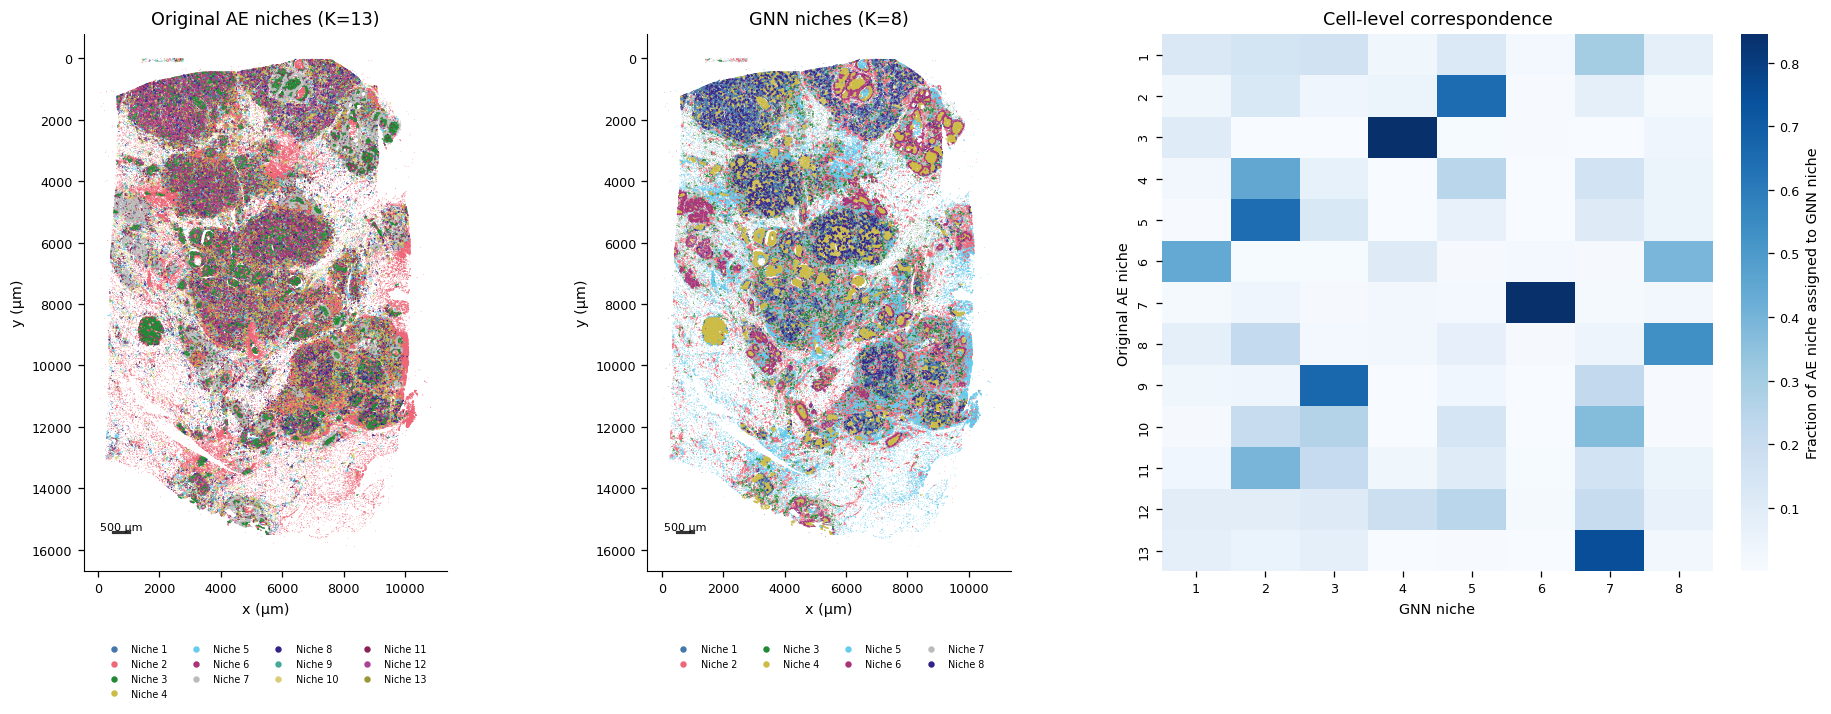

,Value
Cells,699110
Original AE K,13
GNN K,8
Adjusted Rand index,0.295813
Normalized mutual information,0.357091
Comparison scope,Descriptive same-tissue correspondence; original AE used overlapping random folds


All PNG (600 dpi), editable-text PDF, and result tables: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn
Checkpoint, Z, P, H, native CCC reconstruction, training and K-selection records are saved separately.


In [10]:
fig,comparison=report.comparison();show(fig);display(comparison)
print('All PNG (600 dpi), editable-text PDF, and result tables:', OUTPUT)
print('Checkpoint, Z, P, H, native CCC reconstruction, training and K-selection records are saved separately.')